### Cell 01 | Case B: Crossing with square cutout — strain inversion

**Experiment:** a 300 × 200 ft rectangular shear plane with spatially uniform slip on its retained area. The tensile ellipse has half its reference total height (4,000 → 2,000 ft), with center, length, strike and dip preserved; its unit response is recomputed. The shear plane retains the original strike/dip; its 200-ft height is centered on the existing monitoring-well plane intersection.

The original along-strike gap is recovered from the reference geometry (approximately 34.6686 ft). Case A stops short by that gap. Case B extends past the well by the same gap and removes a square of side twice the gap, centered exactly on the continuous well/plane intersection. The square reaches the near edge, forming a notch; it is a zero-slip source region. The closest sampled DAS channel is reported separately from the exact geometric crossing.

**Objective:** 2-hour strain profiles. The baseline fits the existing three temporal-law amplitudes with the revised tensile and small-shear Green's functions. The inversion independently scales the matching baseline components. This is a controlled geometry sensitivity test, not a magnitude-derived rupture-size estimate. Similarity between the two sources is tested, not imposed.

**Scientific boundary:** a cutout changes the physical slip-support area; it is not assumed to remove only numerical error. The spatially uniform shear amplitude is one scalar per time, with no spatial taper, fitted gradient or additional slip patch.

### Cell 02 | Run instructions, assumptions and append-only revision record

Run this experiment from its own directory. For rate fitting, execute **01 → 02** (Case A) or **03 → 04** (Case B). For strain fitting, execute **05 → 06** (Case A) or **07 → 08** (Case B). Each inversion needs its corresponding baseline output and performs zero DDM solves. Four-hour and two-hour objectives must use matching baselines; this notebook is configured for 2-hour strain fitting.

The parent reference project supplies the unchanged observations and reference geometry. The existing sibling DDM package supplies the elastic solver. If this experiment is moved, set `FERVO_REFERENCE_PROJECT` to the local reference project before execution. Publication copies contain notebook sources only; raw data, caches and generated outputs stay local. New outputs are isolated under `output/<case>/rate_fit_2h/` or `output/<case>/strain_fit_2h/`, according to the fitting target.

Dependencies: the same NumPy, pandas, SciPy, Matplotlib, nbformat/ipykernel environment and local DDM/JIN dependencies used by the reference notebooks. Each run exports actual versions. The inherited tested system is Python 3.14.7 on macOS 15.7.9 x86_64; portability to other systems is not established.

Times are fixed UTC−7 in 2025: T1 = Feb 24 12:00, T2 = Feb 28 00:00, T3 = Mar 6 00:00. Original finite-sample masks, rate preprocessing and strain reference are retained. The unresolved observed/model preprocessing differences identified in the rate audit are not silently changed in this geometry-only experiment. No new uncertainty estimates or physical calibration are claimed.

The tensile ellipse is reduced from 4,000 to 2,000 ft in total height about its existing center, without changing its length, strike or dip. The new unit response is checked with 201/401/801 uniform-opening strips; the final relative mesh change must be below 2%. Its along-strike edge clearance is recomputed because reducing ellipse height changes that clearance at the well elevation. The new shear unit responses use analytic rectangles and a refined sampling of the same smoothed monitoring-well path, with a 10-m gauge and sampling/subdivision convergence tests. Reported gap is along strike at the plane crossing, not a minimum three-dimensional well distance.

The existing baseline time laws are reused, but their three global amplitudes are refitted to the observations for each revised geometry and target. The strain-rate inverse permits signed rate scales; the strain inverse uses nonnegative component scales with no rate term. The first two-hour strain mean is the reference (its tensile scale is unidentifiable); subsequent fitted means are reconstructed as a continuous, sign-preserving slip history, and rates are analytic derivatives used only for diagnostics. No temporal smoothing is added. Source dimensions are user-selected test values, not established from microseismic magnitudes.

#### Inherited source revision record
Revision history: **2026-09-19 23:52 MDT** — initial two-step implementation, restored raw observations, mesh and derivative checks, sign-preserving sub-window reconstruction. **2026-09-20 17:19:01 MDT** — final figure review: move plane annotations and pressure legend out of the data, separate 3D labels, and retain the tested numerical model unchanged. **2026-09-20 18:53:13 MDT** — number all cells; share bottom-only date/time axes; update color limits; add pressure/slip figures and the separate strain-rate fitting pair.
**2026-09-20 22:24:23 MDT** — reorganized every code section into a numbered title/introduction followed by numbered code; doubled plot typography; added recorded pressure-stage labels, stronger paired profile overlays and simulated-waterfall summaries. Created this two-hour rate-fitting notebook with 114 windows and separate output files; inherited earlier history describes its four-hour source.

#### Experiment revision record
- **2026-09-22 00:30:23 MDT** — Initial experimental notebook construction.
- **2026-09-22 00:34:29 MDT** — Stabilize cache geometry fingerprints below 1e-8 ft, enforce monotone interpolation and rerun numerical checks. Created Case B inversion from 06_Independent_Slip_Rate_2h_Inversion.ipynb; replaced only shear geometry, preserved tensile response and data/temporal conventions, added paired geometry/Green's-function comparisons and convergence checks. Each title/introduction and following code share one visible number.
- **2026-09-22 00:50:06 MDT** — Removed the inherited comparison to four-hour histories from a different geometry. Re-executed fitting/export checks; the new inversion itself is unchanged. Comparisons to the original model use its own matching two-hour metrics.

- **2026-09-22 22:49:18 MDT** — Create this separate two-hour strain-targeted notebook; halve F1 total height from 4,000 to 2,000 ft about its fixed center, recompute/check its elastic response and refit the selected objective. Preserve F2 geometry and all data/time conventions. Validate matching case/target/height before inversion; update geometry views and exports.

- **2026-09-22 22:52:42 MDT** — Stabilize the half-height response cache across kernels using the survey content hash, sampling/smoothing settings, geometry and solver hashes; verify a fresh cache with the same mesh convergence requirement.


### Cell 03 | Imports, isolated paths and fitting configuration

Select this geometry case and preserve the reference data, units and plotting settings.

In [1]:
# Cell 03 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 03 | Modified 2026-09-22 00:34:29 MDT — Imports, isolated paths and fitting configuration
# Purpose: Select this geometry case and preserve the reference data, units and plotting settings.
# Cell 03 | Modified 2026-09-20 22:37:10 MDT — Imports, paths and plotting settings
# Purpose: Load dependencies, choose the fitting objective and window length, and set text sizes to at least twice the previous values.
from pathlib import Path
import hashlib
import json
import platform
import sys
import warnings
import os
# Modified 2026-09-19 23:34 MDT — keep the Matplotlib cache inside the local project.
_mpl_cache=Path.cwd()/'output/.matplotlib'
_mpl_cache.mkdir(parents=True,exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR',str(_mpl_cache))
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import nnls
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import matplotlib.patheffects as patheffects

# Isolate the experiment while reading immutable reference observations.
_here=Path.cwd().resolve()
EXPERIMENT=_here if _here.name=='Fervo_Small_Shear_Test' else _here/'Fervo_Small_Shear_Test'
assert EXPERIMENT.is_dir(), 'Run from the experiment directory or its parent project.'
PROJECT=Path(os.environ.get('FERVO_REFERENCE_PROJECT',str(EXPERIMENT.parent))).resolve()
V1=PROJECT.parent/'V1_DDM'
FIT_TARGET='strain'
TENSILE_HEIGHT_FACTOR=.5
TARGET_INDEX={'rate':0,'strain':1}[FIT_TARGET]
WINDOW_HOURS=2
CASE='crossing_cutout'
DATA_OUT=PROJECT/'output'
OUT=EXPERIMENT/'output'/CASE/f'{FIT_TARGET}_fit_{WINDOW_HOURS}h'
OUT.mkdir(parents=True,exist_ok=True)
T1, T2, T3 = map(pd.Timestamp, ['2025-02-24 12:00','2025-02-28 00:00','2025-03-06 00:00'])
EDGES = pd.date_range(T1,T3,freq=f'{WINDOW_HOURS}h').as_unit('ns')
CENTERS = EDGES[:-1]+pd.Timedelta(hours=WINDOW_HOURS/2)
FT_TO_MM = 304.8
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':20,'axes.titlesize':24,'axes.labelsize':20,'xtick.labelsize':20,'ytick.labelsize':20,'legend.fontsize':20,'figure.titlesize':24,'pdf.fonttype':42,'svg.fonttype':'none'})

### Cell 04 | Observation support and mean profiles

Average every native sample within each fitting window. Integrate valid adjacent rates and preserve missing-data masks.

In [2]:
# Cell 04 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 04 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 04 | Modified 2026-09-20 22:37:10 MDT — Observation support and mean profiles
# Purpose: Average every native sample within each fitting window. Integrate valid adjacent rates and preserve missing-data masks.
def profiles(values, time, mask=None):
    """Return depth-by-window sample means on the supplied observation support."""
    values = np.asarray(values,float)
    if mask is not None:
        values = np.where(mask,values,np.nan)
    result=[]
    for lo,hi in zip(EDGES[:-1],EDGES[1:]):
        chunk=values[..., (time>=lo)&(time<hi)]
        count=np.isfinite(chunk).sum(axis=-1)
        result.append(np.divide(np.nansum(chunk,axis=-1),count,out=np.full(count.shape,np.nan),where=count>0))
    return np.stack(result,axis=-1)


def integrate_observed(rate,time):
    """Integrate valid adjacent rates to millistrain; hold offset, do not bridge gaps."""
    dt=np.diff(time.asi8)/1e9
    valid=np.isfinite(rate)
    increments=(rate[:,:-1]+rate[:,1:])*.5*dt/1e6
    increments=np.where(valid[:,:-1]&valid[:,1:]&(dt[None,:]<=20),increments,0.)
    strain=np.column_stack([np.zeros(len(rate)),np.cumsum(increments,axis=1)])
    strain[~valid]=np.nan
    strain-=profiles(strain,time)[:,[0]]
    return strain


def load_observations():
    """Return saved rate, cumulative strain, depths, time, support and 2-hour profiles."""
    with np.load(DATA_OUT/'observations_through_20250306.npz') as z:
        rate,depth,time=z['rate'],z['depth'],pd.DatetimeIndex(z['time_ns'])
    strain=integrate_observed(rate,time)
    support=np.isfinite(rate)
    assert np.all(support==support[[0]]), 'Partial-depth gaps require depth-specific slip averaging.'
    assert time.is_monotonic_increasing and not time.has_duplicates
    return dict(rate=rate,strain=strain,depth=depth,time=time,support=support,
                profiles=np.stack([profiles(rate,time),profiles(strain,time)]))

### Cell 05 | Forward model and residual metrics

Define the prescribed time laws, convert component slip to strain/rate, and score the predicted profiles.

In [3]:
# Cell 05 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 05 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 05 | Modified 2026-09-20 22:37:10 MDT — Forward model and residual metrics
# Purpose: Define the prescribed time laws, convert component slip to strain/rate, and score the predicted profiles.
def time_laws(time):
    """Return three unit-amplitude time laws and analytic derivatives per second."""
    t=pd.DatetimeIndex(time)
    d1,d2=(T2-T1).total_seconds(),(T3-T2).total_seconds()
    x=np.clip((t-T1).total_seconds().to_numpy()/d1,0,1)
    y=np.clip((t-T2).total_seconds().to_numpy()/d2,0,1)
    laws=np.array([x*x,y,y*y])
    speeds=np.array([np.where((t>=T1)&(t<T2),2*x/d1,0),
                     np.where((t>=T2)&(t<=T3),1/d2,0),
                     np.where((t>=T2)&(t<=T3),2*y/d2,0)])
    return laws,speeds


def forward_components(unit,amounts,speeds,obs,reference=None):
    """Map signed slips/speeds in mm to component strain and rate, with one reference."""
    strain=unit[:,:,None]*amounts[:,None,:]/FT_TO_MM*1e3
    rate=unit[:,:,None]*speeds[:,None,:]/FT_TO_MM*1e9
    if reference is None:
        reference=profiles(amounts,obs['time'],obs['support'][[0]])[:,0]
    strain-=unit[:,:,None]*reference[:,None,None]/FT_TO_MM*1e3
    pp=np.stack([profiles(rate,obs['time'],obs['support']),profiles(strain,obs['time'],obs['support'])],axis=1)
    return dict(amounts=amounts,speeds=speeds,rate=rate,strain=strain,profiles=pp,reference=reference)


def fit_metrics(obs,model):
    """Return unweighted profile RMSE and target-RMS-normalized RMSE for both quantities."""
    rows=[]
    for q,(name,units) in enumerate([('rate','nanostrain/s'),('strain','millistrain')]):
        y=obs['profiles'][q]; pred=model['profiles'][:,q].sum(axis=0)
        mask=np.isfinite(y)&np.isfinite(pred)
        if q==1: mask[:,0]=False
        rmse=np.sqrt(np.mean((pred[mask]-y[mask])**2))
        rows.append(dict(quantity=name,units=units,rmse=float(rmse),relative_rmse=float(rmse/np.sqrt(np.mean(y[mask]**2))),samples=int(mask.sum()),fitted=q==TARGET_INDEX))
    return pd.DataFrame(rows)

### Cell 06 | Injection pressure and figure exports

Load recorded hydraulic-stage numbers and save local figures with shared-axis alignment checks.

In [4]:
# Cell 06 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 06 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 06 | Modified 2026-09-20 22:37:10 MDT — Injection pressure and figure exports
# Modified 2026-09-20 22:29:10 MDT — document physical-aspect geometry column exemption.
# Modified 2026-09-20 22:28:05 MDT — refine rendered label clearance and verification.
# Purpose: Load recorded hydraulic-stage numbers and save local figures with shared-axis alignment checks.
def pressure_data():
    """Read three local injection-well pressure records; return an unshifted MST table."""
    root=V1.parents[2]/'Aleksei/Data/Bearskin Stimulation Data'
    frames=[]
    for well,color in [('1-IA','#E69F00'),('3-PA','#7B3294'),('4-PB','#D55E00')]:
        frame=pd.read_csv(root/f'Bearskin {well} Pressure.csv')
        frame['time']=pd.to_datetime(frame.MSTTIMESTAMP)
        frame['stage_number']=pd.to_numeric(frame.STAGENUMBER,errors='coerce')
        frame['pressure_psi']=pd.to_numeric(frame.PRESSURE_PSI,errors='coerce')
        frame=frame.loc[frame.time.between(T1,T3)].copy()
        frame['well']='Bearskin '+well; frame['color']=color
        frames.append(frame[['time','pressure_psi','well','color','stage_number']])
    return pd.concat(frames,ignore_index=True)


def save_figure(fig,name,axes=None):
    """Save PNG/PDF plus measured axes rectangles; reject inconsistent shared x extents."""
    fig.canvas.draw()
    boxes=[]
    for ax in (axes or []):
        box=ax.get_position()
        boxes.append(dict(left_pt=box.x0*fig.get_figwidth()*72,right_pt=box.x1*fig.get_figwidth()*72,bottom_pt=box.y0*fig.get_figheight()*72,top_pt=box.y1*fig.get_figheight()*72))
    if len(boxes)>1:
        assert np.ptp([b['left_pt'] for b in boxes])<1.5
        assert np.ptp([b['right_pt'] for b in boxes])<1.5
        # Optional local figure QA; not a dependency for normal notebook execution.
        qa_scripts=os.environ.get('FERVO_FIGURE_QA_SCRIPTS')
        if qa_scripts:
            if qa_scripts not in sys.path: sys.path.insert(0,qa_scripts)
            from audit_panel_alignment import require_matplotlib_panel_alignment
            require_matplotlib_panel_alignment(fig,axes=axes,json_out=OUT/f'{name}_alignment.json',strict=True)
    if axes is None and len(fig.axes)>=4 and os.environ.get('FERVO_FIGURE_QA_SCRIPTS'):
        qa_scripts=os.environ['FERVO_FIGURE_QA_SCRIPTS']
        if qa_scripts not in sys.path: sys.path.insert(0,qa_scripts)
        from audit_panel_alignment import require_matplotlib_panel_alignment
        # Equal-aspect physical projections intentionally differ in width; compare row edges.
        require_matplotlib_panel_alignment(fig,axes=fig.axes[:4],panel_ids=['a','b','c','d'],
            row_groups=[['a','b'],['c','d']],column_groups=[],
            exemptions=[{'panels':['a','b','c','d'],'checks':['column'],
                         'reason':'Equal physical aspect ratios in XY/XZ/YZ and a 3D view require different widths; row heights and edges remain comparable.'}],
            json_out=OUT/f'{name}_alignment.json',strict=True)
    (OUT/f'{name}_layout.json').write_text(json.dumps(boxes,indent=2))
    fig.savefig(OUT/f'{name}.png',dpi=300)
    fig.savefig(OUT/f'{name}.pdf',dpi=300)
    fig.savefig(OUT/f'{name}.svg',dpi=300)
    display(fig)
    plt.close(fig)

### Cell 07 | Visible waterfall profiles

Overlay all observed profiles in black and simulated profiles in thicker dashed green, with a common amplitude scale and legend.

In [5]:
# Cell 07 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 07 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 07 | Modified 2026-09-20 22:37:10 MDT — Visible waterfall profiles
# Purpose: Overlay all observed profiles in black and simulated profiles in thicker dashed green, with a common amplitude scale and legend.
def profile_legend(fig, y=.985):
    """Use one figure-level key for the paired profile curves."""
    handles=[Line2D([],[],color='black',lw=1.6,label='Observed profile'),
             Line2D([],[],color='#00852B',lw=2.4,ls='--',label='Simulated profile')]
    fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,y),ncol=2,frameon=False)


def waterfall(ax,obs,model,quantity,background='observed',scale=None):
    """Draw a waterfall and every fitted window profile at its center time."""
    key=('rate','strain')[quantity]
    values=obs[key] if background=='observed' else model[key].sum(axis=0)
    values=np.where(obs['support'],values,np.nan)
    # Display-only 10-minute means; profile fitting retains all native samples.
    frame=pd.DataFrame(values.T,index=obs['time']).resample('10min').mean()
    cmap=plt.get_cmap('seismic').copy(); cmap.set_bad('#bbbbbb')
    lim=(.3,.15)[quantity]
    image=ax.pcolormesh(frame.index,obs['depth'],frame.to_numpy().T,cmap=cmap,vmin=-lim,vmax=lim,shading='auto',rasterized=True)
    observed=obs['profiles'][quantity]; simulated=model['profiles'][:,quantity].sum(axis=0)
    if scale is None:
        scale=max(np.nanpercentile(np.abs(np.r_[observed.ravel(),simulated.ravel()]),98),1e-12)
    # A common amplitude-to-time mapping for observed/simulated; halve spacing at 2 h.
    width_days=.055*(WINDOW_HOURS/4)/scale
    x=mdates.date2num(CENTERS)
    for j,anchor in enumerate(x):
        ax.plot(anchor+observed[:,j]*width_days,obs['depth'],color='black',lw=1.6,zorder=5,
                path_effects=[patheffects.Stroke(linewidth=2.8,foreground='white'),patheffects.Normal()])
        ax.plot(anchor+simulated[:,j]*width_days,obs['depth'],color='#00852B',ls='--',lw=2.4,zorder=6,
                path_effects=[patheffects.Stroke(linewidth=3.5,foreground='white'),patheffects.Normal()])
    ax.set(ylim=(10500,10200),xlim=(T1,T3),ylabel='Measured depth (ft)')
    ax.set_title(f'{background.capitalize()} {key} waterfall | {WINDOW_HOURS}-hour mean profiles',pad=48)
    for t,label in [(T1,'T1'),(T2,'T2'),(T3,'T3')]:
        ax.axvline(t,color='#B36B00',ls='--',lw=1.2)
        ax.text(t,1.012,label,transform=ax.get_xaxis_transform(),color='#996000',fontsize=16,ha='center',va='bottom')
    geometry_file=OUT/'fixed_plane_geometry.csv'
    if geometry_file.exists():
        for k,row in pd.read_csv(geometry_file).iterrows():
            color=['#B36B00','teal'][k]
            ax.axhline(row.plane_crossing_md_ft,color=color,ls='--',lw=1.2)
            ax.annotate(f'F{k+1} plane extension: {row.plane_crossing_md_ft:.1f} ft',xy=(.13+.43*k,1),xycoords='axes fraction',xytext=(0,10),textcoords='offset points',ha='left',va='bottom',fontsize=16,color=color)
    return image

### Cell 08 | Pressure, slip and shared time axes

Label contiguous recorded stage intervals above the pressure curves and align pressure and continuous slip histories.

In [6]:
# Cell 08 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 08 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 08 | Modified 2026-09-20 22:37:10 MDT — Pressure, slip and shared time axes
# Modified 2026-09-20 22:28:05 MDT — refine rendered label clearance and verification.
# Purpose: Label contiguous recorded stage intervals above the pressure curves and align pressure and continuous slip histories.
def pressure_slip_panels(axes,obs,model,injection,title):
    """Plot recorded pressure/stage metadata and continuous tensile/shear slip."""
    for well,frame in injection.groupby('well',sort=False):
        axes[0].plot(frame.time,frame.pressure_psi,lw=1.5,color=frame.color.iloc[0],label=well)
    # The supplied files repeat the same stage timeline across all three gauges.
    # Check that agreement before drawing a shared band; never infer stages from peaks.
    stage_table=injection.pivot(index='time',columns='well',values='stage_number').sort_index()
    assert stage_table.nunique(axis=1,dropna=False).max()==1, 'Gauge stage records disagree.'
    stage=stage_table.iloc[:,0]
    changes=stage.ne(stage.shift()) & ~(stage.isna() & stage.shift().isna())
    runs=[]
    for _,part in stage.groupby(changes.cumsum()):
        if part.notna().any():
            runs.append((part.index[0],part.index[-1],int(part.iloc[0])))
    max_pressure=float(injection.pressure_psi.max())
    axes[0].set_ylim(0,max_pressure*1.50)
    for i,(lo,hi,number) in enumerate(runs):
        center=lo+(hi-lo)/2
        # Two alternating lanes avoid collisions between adjacent short stages.
        level=max_pressure*(1.19+.18*(i%2))
        axes[0].text(center,level,str(number),ha='center',va='center',fontsize=18)
    axes[0].set(ylabel='Injection pressure (psi)')
    axes[0].set_title('Injection pressure | recorded stage numbers above curves',pad=60)
    axes[0].legend(ncol=3,fontsize=20,loc='lower left',bbox_to_anchor=(0,1.015),borderaxespad=0,frameon=False)
    twin=axes[1].twinx()
    axes[1].plot(obs['time'],model['amounts'][0],color='royalblue',lw=2,label='Tensile opening')
    twin.plot(obs['time'],np.abs(model['amounts'][1]),color='firebrick',lw=2,label='Shear magnitude')
    axes[1].set(ylabel='Tensile slip (mm)')
    axes[1].set_title(title,pad=58)
    twin.set_ylabel('|Shear slip| (mm)',color='firebrick')
    axes[1].yaxis.label.set_color('royalblue')
    axes[1].legend(handles=[Line2D([],[],color='royalblue',label='Tensile'),Line2D([],[],color='firebrick',label='|Shear|')],loc='lower left',bbox_to_anchor=(0,1.01),ncol=2,frameon=False)
    for ax in axes[:2]: ax.axvline(T2,color='#B36B00',ls='--',lw=1.2)
    return twin


def shared_time_axis(axes):
    """Show date/time ticks only on the bottom shared axis, in fixed UTC−7."""
    for ax in axes: ax.set_xlim(T1,T3)
    axes[-1].xaxis.set_major_locator(mdates.DayLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d/%y\n%H:%M'))
    for ax in axes[:-1]:
        assert ax.get_shared_x_axes().joined(ax,axes[-1])
        ax.tick_params(axis='x',which='both',bottom=False,top=False,labelbottom=False,labeltop=False)
        ax.set_xlabel('')
    axes[-1].tick_params(axis='x',which='both',bottom=True,labelbottom=True,top=False,labeltop=False)
    axes[-1].set_xlabel('Time (fixed UTC−7)')

### Cell 09 | Diagnostic figure layouts

Create pressure/slip figures and combined observed or simulated waterfall figures with enlarged labels.

In [7]:
# Cell 09 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 09 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 09 | Modified 2026-09-20 22:37:10 MDT — Diagnostic figure layouts
# Purpose: Create pressure/slip figures and combined observed or simulated waterfall figures with enlarged labels.
def plot_pressure_slip(obs,model,injection,name):
    """Save pressure with recorded stages and slip, sharing one time axis."""
    fig,axes=plt.subplots(2,1,figsize=(30,11),sharex=True)
    fig.subplots_adjust(left=.075,right=.90,bottom=.13,top=.84,hspace=.65)
    pressure_slip_panels(axes,obs,model,injection,'Tensile and shear slip history')
    shared_time_axis(axes)
    save_figure(fig,f'{name}_pressure_slip',list(axes))
    return fig


def plot_summary(obs,model,injection,name,background='observed'):
    """Align pressure, slip, and two diagnostic waterfalls on one timeline."""
    fig=plt.figure(figsize=(30,22))
    gs=fig.add_gridspec(4,2,height_ratios=[1.25,1,2.3,2.3],width_ratios=[1,.016],left=.075,right=.91,bottom=.065,top=.87,hspace=.62,wspace=.06)
    axes=[fig.add_subplot(gs[0,0])]
    axes.extend(fig.add_subplot(gs[i,0],sharex=axes[0]) for i in range(1,4))
    pressure_slip_panels(axes,obs,model,injection,'Tensile and shear slip history')
    for q,ax in enumerate(axes[2:]):
        im=waterfall(ax,obs,model,q,background=background)
        fig.colorbar(im,cax=fig.add_subplot(gs[q+2,1]),label=('Rate (nanostrain/s)','Strain (millistrain)')[q])
    profile_legend(fig,y=.98)
    shared_time_axis(axes)
    suffix='' if background=='observed' else '_simulated_summary'
    save_figure(fig,name+suffix,axes)
    return fig


def plot_comparison(obs,model,name):
    """Compare observed/simulated waterfalls with the same color and wiggle scales."""
    for background in ['observed','simulated']:
        fig=plt.figure(figsize=(30,15))
        gs=fig.add_gridspec(2,2,width_ratios=[1,.016],left=.075,right=.91,bottom=.105,top=.85,hspace=.40,wspace=.06)
        axes=[]
        for q in range(2):
            ax=fig.add_subplot(gs[q,0],sharex=axes[0] if axes else None); axes.append(ax)
            im=waterfall(ax,obs,model,q,background)
            fig.colorbar(im,cax=fig.add_subplot(gs[q,1]),label=('Rate (nanostrain/s)','Strain (millistrain)')[q])
        profile_legend(fig,y=.98)
        shared_time_axis(axes)
        save_figure(fig,f'{name}_{background}',axes)

### Cell 10 | Component tables and runtime provenance

Export per-window component slips, strain and rate profiles, residual metrics, and actual dependency versions.

In [8]:
# Cell 10 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 10 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 10 | Modified 2026-09-20 22:37:10 MDT — Component tables and runtime provenance
# Purpose: Export per-window component slips, strain and rate profiles, residual metrics, and actual dependency versions.
def export_components(obs,model,prefix,coefficients=None):
    """Write per-component, per-2h slip, strain and strain-rate CSVs and a compact NPZ."""
    mean_amount=profiles(model['amounts'],obs['time'],obs['support'][[0]])
    mean_speed=profiles(model['speeds'],obs['time'],obs['support'][[0]])
    for k,component in enumerate(['tensile','shear']):
        slips=pd.DataFrame({'window_start':EDGES[:-1],'window_end':EDGES[1:],'center_time':CENTERS,'mean_signed_slip_mm':mean_amount[k],'mean_absolute_slip_mm':np.abs(mean_amount[k]),'mean_signed_slip_rate_mm_s':mean_speed[k]})
        if coefficients is not None: slips[f'{FIT_TARGET}_baseline_scale']=coefficients[k]
        slips.to_csv(OUT/f'{prefix}_{component}_slip_2h.csv',index=False)
        frame=pd.DataFrame({'center_time':np.repeat(CENTERS,len(obs['depth'])),'md_ft':np.tile(obs['depth'],len(CENTERS)),
            'strain_millistrain':model['profiles'][k,1].T.ravel(),'strain_rate_nanostrain_s':model['profiles'][k,0].T.ravel()})
        frame.to_csv(OUT/f'{prefix}_{component}_profiles_2h.csv',index=False)
    np.savez_compressed(OUT/f'{prefix}_profiles_2h.npz',depth_ft=obs['depth'],centers_ns=CENTERS.asi8,
                        component_profiles=model['profiles'],mean_slip_mm=mean_amount,mean_slip_rate_mm_s=mean_speed,observed_profiles=obs['profiles'])
    fit_metrics(obs,model).to_csv(OUT/f'{prefix}_metrics.csv',index=False)


def environment_report():
    """Return actual runtime and dependency versions; no claims about untested platforms."""
    return dict(system=platform.platform(),python=sys.version.split()[0],numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)

### Cell 11 | Load the matching small-shear baseline

Verify geometry case, recomputed half-height tensile response and fitting target, depth/time support and reconstructed baseline profiles; run no new DDM solves.

In [9]:
# Cell 11 | Modified 2026-09-22 22:52:42 MDT — Key the tensile cache by survey contents and fixed solver settings, avoiding round-off-sensitive interpolated coordinates.
# Cell 11 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 11 | Modified 2026-09-22 00:34:29 MDT — Load the matching small-shear baseline
# Purpose: Verify geometry case, half-height tensile response, depth/time support and reconstructed baseline profiles; run no new DDM solves.
# Cell 11 | Modified 2026-09-20 22:37:10 MDT — Load the strain-fitted baseline; no DDM computation
# Purpose: Load the matching baseline and verify depth/time arrays and reconstructed profiles before inversion.
obs=load_observations()
with np.load(OUT/'baseline_for_inversion.npz') as z:
    unit=z['unit']; amplitudes=z['amplitudes']; base_amount=z['amounts']; base_speed=z['speeds']
    base_profiles=z['component_profiles']; base_reference=z['reference_mm']
    baseline_case=str(z['case']); baseline_target=str(z['fit_target'])
    baseline_height_factor=float(z['tensile_height_factor'])
    baseline_tensile_signature=str(z['tensile_signature']); baseline_signature=str(z['signature'])
    np.testing.assert_array_equal(z['time_ns'],obs['time'].asi8)
    np.testing.assert_array_equal(z['depth'],obs['depth'])
baseline=forward_components(unit,base_amount,base_speed,obs,reference=base_reference)
np.testing.assert_allclose(baseline['profiles'],base_profiles,atol=1e-12)
# Reject a baseline from another objective, case, or tensile height.
assert baseline_case==CASE and baseline_target==FIT_TARGET
assert np.isclose(baseline_height_factor,TENSILE_HEIGHT_FACTOR)
geometry_definition=json.loads((OUT/'geometry_definition.json').read_text())
assert geometry_definition['case']==CASE
assert np.isclose(geometry_definition['tensile']['geometry']['height_ft'],2000.)
assert geometry_definition['tensile_signature']==baseline_tensile_signature
assert geometry_definition['response_signature']==baseline_signature
with np.load(EXPERIMENT/'output/half_height_tensile_response_cache_v2.npz') as z:
    assert str(z['signature'])==baseline_tensile_signature
    np.testing.assert_array_equal(unit[0],z['unit'])

reference=base_reference
base_means=profiles(base_amount,obs['time'],obs['support'][[0]])


### Cell 12 | Independently fit each two-hour strain profile

Fit nonnegative tensile/shear baseline scales to strain only; exclude the reference window and reconstruct continuous slips preserving the fitted window means. Rates are derivative diagnostics.

In [10]:
# Cell 12 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 12 | Modified 2026-09-20 22:34:05 MDT — Independent two-column fits (tensile only before T2)
# Purpose: Fit independent tensile/shear coefficients in each window and verify reconstruction, identifiability, slip continuity and rate consistency.
scales=np.full((2,len(CENTERS)),np.nan)
fitted_means=np.full_like(scales,np.nan)
fitted_means[:,0]=reference
diagnostics=[]
for j,t in enumerate(CENTERS):
    if j==0:
        diagnostics.append(dict(center_time=t,rank=0,condition=np.nan,status='reference window: scales unidentifiable'))
        continue
    active=[0] if t<T2 else [0,1]
    y=obs['profiles'][1,:,j]
    columns=base_profiles[active,1,:,j].T
    valid=np.isfinite(y)&np.isfinite(columns).all(axis=1)
    if valid.sum()<len(active):
        raise ValueError(f'Insufficient observations at {t}; no extrapolated fit will be substituted.')
    norms=np.linalg.norm(columns[valid],axis=0)
    if np.any(norms<1e-14):
        raise ValueError(f'Zero baseline at {t}: scale not identifiable; revise baseline or use unit-slip basis explicitly.')
    scaled=columns[valid]/norms
    assert np.linalg.matrix_rank(scaled)==len(active),f'Rank-deficient strain fit at {t}'
    c,_=nnls(scaled,y[valid]); c/=norms
    scales[:,j]=0.; scales[active,j]=c
    fitted_means[:,j]=reference+scales[:,j]*(base_means[:,j]-reference)
    diagnostics.append(dict(center_time=t,rank=int(np.linalg.matrix_rank(scaled)),condition=float(np.linalg.cond(scaled)),status='independent strain-only fit'))
scales[1,0]=0.
fitted_means[1,CENTERS<T2]=0.
diagnostics=pd.DataFrame(diagnostics)
display(diagnostics.tail())


def reconstruct_history(means,time,support):
    """Return continuous, window-mean-preserving quadratic slips and analytic derivatives.

    Each window is independent in the fit. Neighboring means define boundary values;
    a quadratic correction enforces the fitted mean on the exact observation support.
    These interpolation-derived rates are diagnostics, not separately inverted data.
    """
    # Modified 2026-09-19 23:52 MDT — prevent interpolation-only sign reversals.
    # Nonnegative window means are fitted independently; this only chooses the sub-window path.
    signs=np.array([1.,-1.])
    magnitudes=means*signs[:,None]
    assert magnitudes.min()>-1e-12
    boundaries=np.zeros((2,len(EDGES)))
    boundaries[:,1:-1]=np.minimum((magnitudes[:,:-1]+magnitudes[:,1:])/2,1.4*np.minimum(magnitudes[:,:-1],magnitudes[:,1:]))
    boundaries[:,-1]=np.clip(magnitudes[:,-1]+.5*(magnitudes[:,-1]-magnitudes[:,-2]),0,1.4*magnitudes[:,-1])
    boundaries[1,EDGES<=T2]=0.
    amounts=np.zeros((2,len(time))); speeds=np.zeros_like(amounts)
    curvature=np.zeros_like(means)
    for j,(lo,hi) in enumerate(zip(EDGES[:-1],EDGES[1:])):
        use=(time>=lo)&(time<hi)
        x=(time[use]-lo).total_seconds().to_numpy()/(hi-lo).total_seconds()
        sampled=support[0,use]
        shape=x*(1-x)
        linear=boundaries[:,[j]]+(boundaries[:,[j+1]]-boundaries[:,[j]])*x
        correction=(magnitudes[:,j]-linear[:,sampled].mean(axis=1))/shape[sampled].mean()
        # A quadratic Bezier curve is nonnegative if all three control values are.
        middle_control=(boundaries[:,j]+boundaries[:,j+1]+correction)/2
        assert middle_control.min()>-1e-10,'Reduce boundary magnitudes for this unusual sample support.'
        curvature[:,j]=correction
        amounts[:,use]=linear+correction[:,None]*shape
        speeds[:,use]=(boundaries[:,[j+1]]-boundaries[:,[j]]+correction[:,None]*(1-2*x))/(hi-lo).total_seconds()
    return amounts*signs[:,None],speeds*signs[:,None],boundaries*signs[:,None],curvature*signs[:,None]


amounts,speeds,boundaries,curvature=reconstruct_history(fitted_means,obs['time'],obs['support'])
final=forward_components(unit,amounts,speeds,obs,reference=reference)
np.testing.assert_allclose(profiles(amounts,obs['time'],obs['support'][[0]]),fitted_means,atol=1e-10)
np.testing.assert_allclose(final['profiles'][:,1,:,1:],base_profiles[:,1,:,1:]*scales[:,None,1:],atol=1e-10)
assert np.all(amounts[1,obs['time']<T2]==0.)
assert np.all(speeds[1,obs['time']<T2]==0.)
assert amounts[0].min()>-1e-10 and amounts[1].max()<1e-10
# Modified 2026-09-19 23:37 MDT — numerical derivative check away from window boundaries.
seconds=(obs['time']-T1).total_seconds().to_numpy()
window_index=np.searchsorted(EDGES.asi8,obs['time'].asi8,side='right')-1
interior=np.r_[False,(window_index[:-2]==window_index[1:-1])&(window_index[1:-1]==window_index[2:]),False]
numeric_rate=np.gradient(amounts,seconds,axis=1,edge_order=2)
np.testing.assert_allclose(numeric_rate[:,interior],speeds[:,interior],atol=1e-9)
np.testing.assert_allclose(final['strain'].sum(axis=0),unit.T@(amounts-reference[:,None])/FT_TO_MM*1e3,atol=1e-12)
baseline_metrics=fit_metrics(obs,baseline); final_metrics=fit_metrics(obs,final)
assert final_metrics.loc[1,'rmse']<=baseline_metrics.loc[1,'rmse']+1e-10
display(pd.concat({'baseline':baseline_metrics,'independent inversion':final_metrics}))

,center_time,rank,condition,status
109,2025-03-05 15:00:00,2,1.005996,independent strain-only fit
110,2025-03-05 17:00:00,2,1.005996,independent strain-only fit
111,2025-03-05 19:00:00,2,1.005996,independent strain-only fit
112,2025-03-05 21:00:00,2,1.005996,independent strain-only fit
113,2025-03-05 23:00:00,2,1.005996,independent strain-only fit


quantity         units      rmse  relative_rmse  \
baseline              0     rate  nanostrain/s  0.071963       0.784626   
                      1   strain   millistrain  0.012898       0.379265   
independent inversion 0     rate  nanostrain/s  0.050537       0.551014   
                      1   strain   millistrain  0.012582       0.369968   

                         samples  fitted  
baseline              0     5016   False  
                      1     4972    True  
independent inversion 0     5016   False  
                      1     4972    True

### Cell 13 | Export this case inversion and diagnostics

Save inferred histories, rates, scales, residuals and geometry-specific provenance without mixing the two experiment cases.

In [11]:
# Cell 13 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 13 | Modified 2026-09-20 22:34:05 MDT — Component exports: inferred slips, exact fitted strains, derivative-consistent rates
# Purpose: Export component histories, fitted profiles and diagnostic metrics; keep fitting-window comparisons explicit.
export_components(obs,final,'inverted',scales)
pd.DataFrame({'time':EDGES,'tensile_mm':boundaries[0],'signed_shear_mm':boundaries[1],'shear_magnitude_mm':np.abs(boundaries[1])}).to_csv(OUT/'inverted_slip_knots_2h.csv',index=False)
diagnostics.to_csv(OUT/'inversion_identifiability.csv',index=False)
pd.DataFrame({'center_time':CENTERS,'c_tensile':scales[0],'c_shear':scales[1]}).to_csv(OUT/'inversion_scaling_coefficients_2h.csv',index=False)
np.savez_compressed(OUT/'inverted_history.npz',time_ns=obs['time'].asi8,amounts_mm=amounts,speeds_mm_s=speeds,scales=scales,boundary_slip_mm=boundaries,quadratic_correction_mm=curvature)
report={'objective':'Independent nonnegative baseline scaling of each two-hour strain profile; no strain-rate term, smoothing penalty or monotonicity constraint.',
    'reference':'First two-hour mean is zero strain by definition; tensile scale is unidentifiable there. Its mean opening is retained from the baseline.',
    'rate_definition':'Analytic derivative of continuous, quadratic-within-window reconstruction; exact observed-support window means. Does not merely scale baseline rate.',
    'fixed_tensile_plane':True,'DDM_solves_in_this_notebook':0,'environment':environment_report(),
    'max_two_column_condition':float(diagnostics.condition.max()),'baseline_strain_rmse':float(baseline_metrics.loc[1,'rmse']),
    'inverted_strain_rmse':float(final_metrics.loc[1,'rmse']),
    'tensile_min_mm':float(amounts[0].min()),'signed_shear_max_mm':float(amounts[1].max()),
    'note':'Absolute zero and unobserved increments across data gaps are not measured. Window mean slip is inferred; within-window rates depend on interpolation.'}
(OUT/'inversion_report.json').write_text(json.dumps(report,indent=2))
display(pd.read_csv(OUT/'inverted_tensile_slip_2h.csv').tail())
display(pd.read_csv(OUT/'inverted_shear_slip_2h.csv').tail())
report.update(case=CASE,fit_target=FIT_TARGET,tensile_response_unchanged=False,tensile_height_ft=2000.,geometry=geometry_definition['comparison'])
(OUT/'inversion_report.json').write_text(json.dumps(report,indent=2))
comparison=pd.concat([pd.read_csv(OUT/f'{model}_metrics.csv').assign(case=CASE,model=model) for model in ['baseline','inverted']],ignore_index=True)
comparison.to_csv(OUT/'baseline_vs_inverted_metrics.csv',index=False)
display(comparison)


,window_start,window_end,center_time,mean_signed_slip_mm,mean_absolute_slip_mm,mean_signed_slip_rate_mm_s,strain_baseline_scale
109,2025-03-05 14:00:00,2025-03-05 16:00:00,2025-03-05 15:00:00,8.788460,8.788460,-0.000005,0.927110
110,2025-03-05 16:00:00,2025-03-05 18:00:00,2025-03-05 17:00:00,8.825326,8.825326,0.000004,0.922577
111,2025-03-05 18:00:00,2025-03-05 20:00:00,2025-03-05 19:00:00,8.846831,8.846831,0.000002,0.916534
112,2025-03-05 20:00:00,2025-03-05 22:00:00,2025-03-05 21:00:00,8.860089,8.860089,0.000002,0.909751
113,2025-03-05 22:00:00,2025-03-06 00:00:00,2025-03-05 23:00:00,8.876521,8.876521,0.000002,0.903412


,window_start,window_end,center_time,mean_signed_slip_mm,mean_absolute_slip_mm,mean_signed_slip_rate_mm_s,strain_baseline_scale
109,2025-03-05 14:00:00,2025-03-05 16:00:00,2025-03-05 15:00:00,-7.925521,7.925521,0.000003,0.807513
110,2025-03-05 16:00:00,2025-03-05 18:00:00,2025-03-05 17:00:00,-7.848458,7.848458,0.000008,0.776484
111,2025-03-05 18:00:00,2025-03-05 20:00:00,2025-03-05 19:00:00,-7.807709,7.807709,0.000004,0.750384
112,2025-03-05 20:00:00,2025-03-05 22:00:00,2025-03-05 21:00:00,-7.784236,7.784236,0.000003,0.727055
113,2025-03-05 22:00:00,2025-03-06 00:00:00,2025-03-05 23:00:00,-7.761568,7.761568,0.000003,0.704802


,quantity,units,rmse,relative_rmse,samples,fitted,case,model
0,rate,nanostrain/s,0.071963,0.784626,5016,False,crossing_cutout,baseline
1,strain,millistrain,0.012898,0.379265,4972,True,crossing_cutout,baseline
2,rate,nanostrain/s,0.050537,0.551014,5016,False,crossing_cutout,inverted
3,strain,millistrain,0.012582,0.369968,4972,True,crossing_cutout,inverted


### Cell 14 | Shared-axis pressure, slip and waterfall diagnostics

Show recorded pressure stages and slip alongside observed and simulated strain-rate/strain waterfalls.

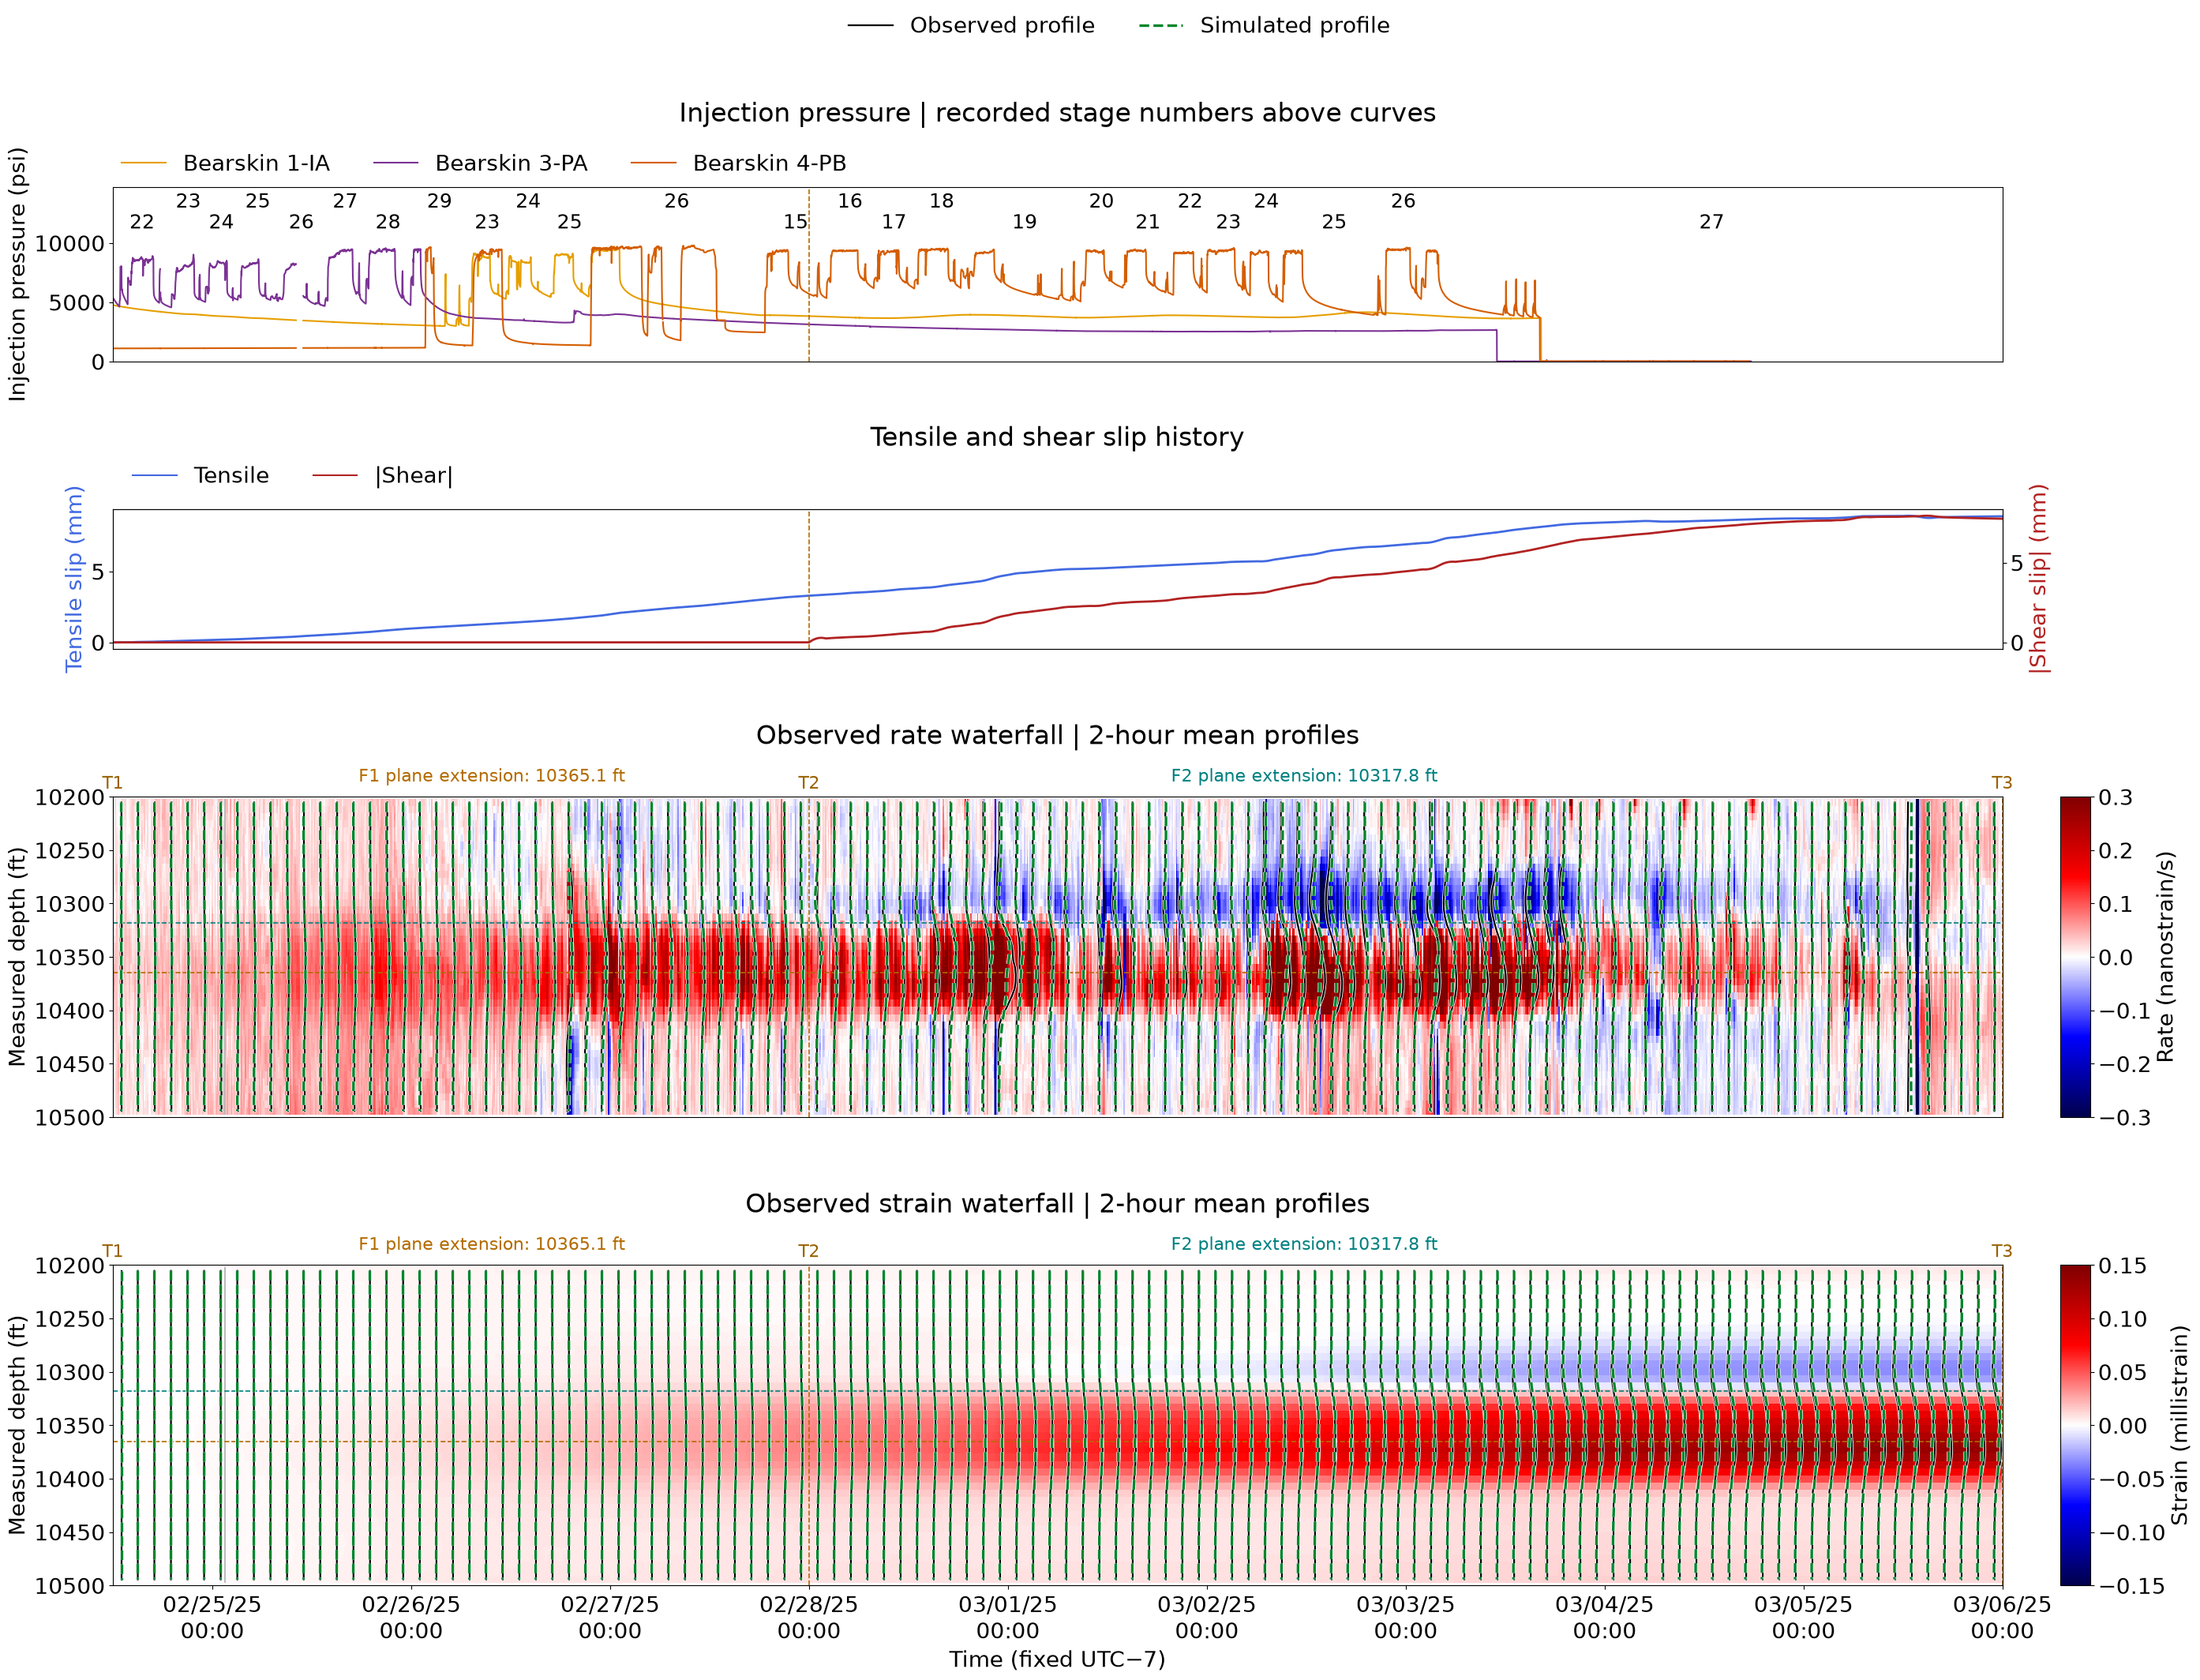

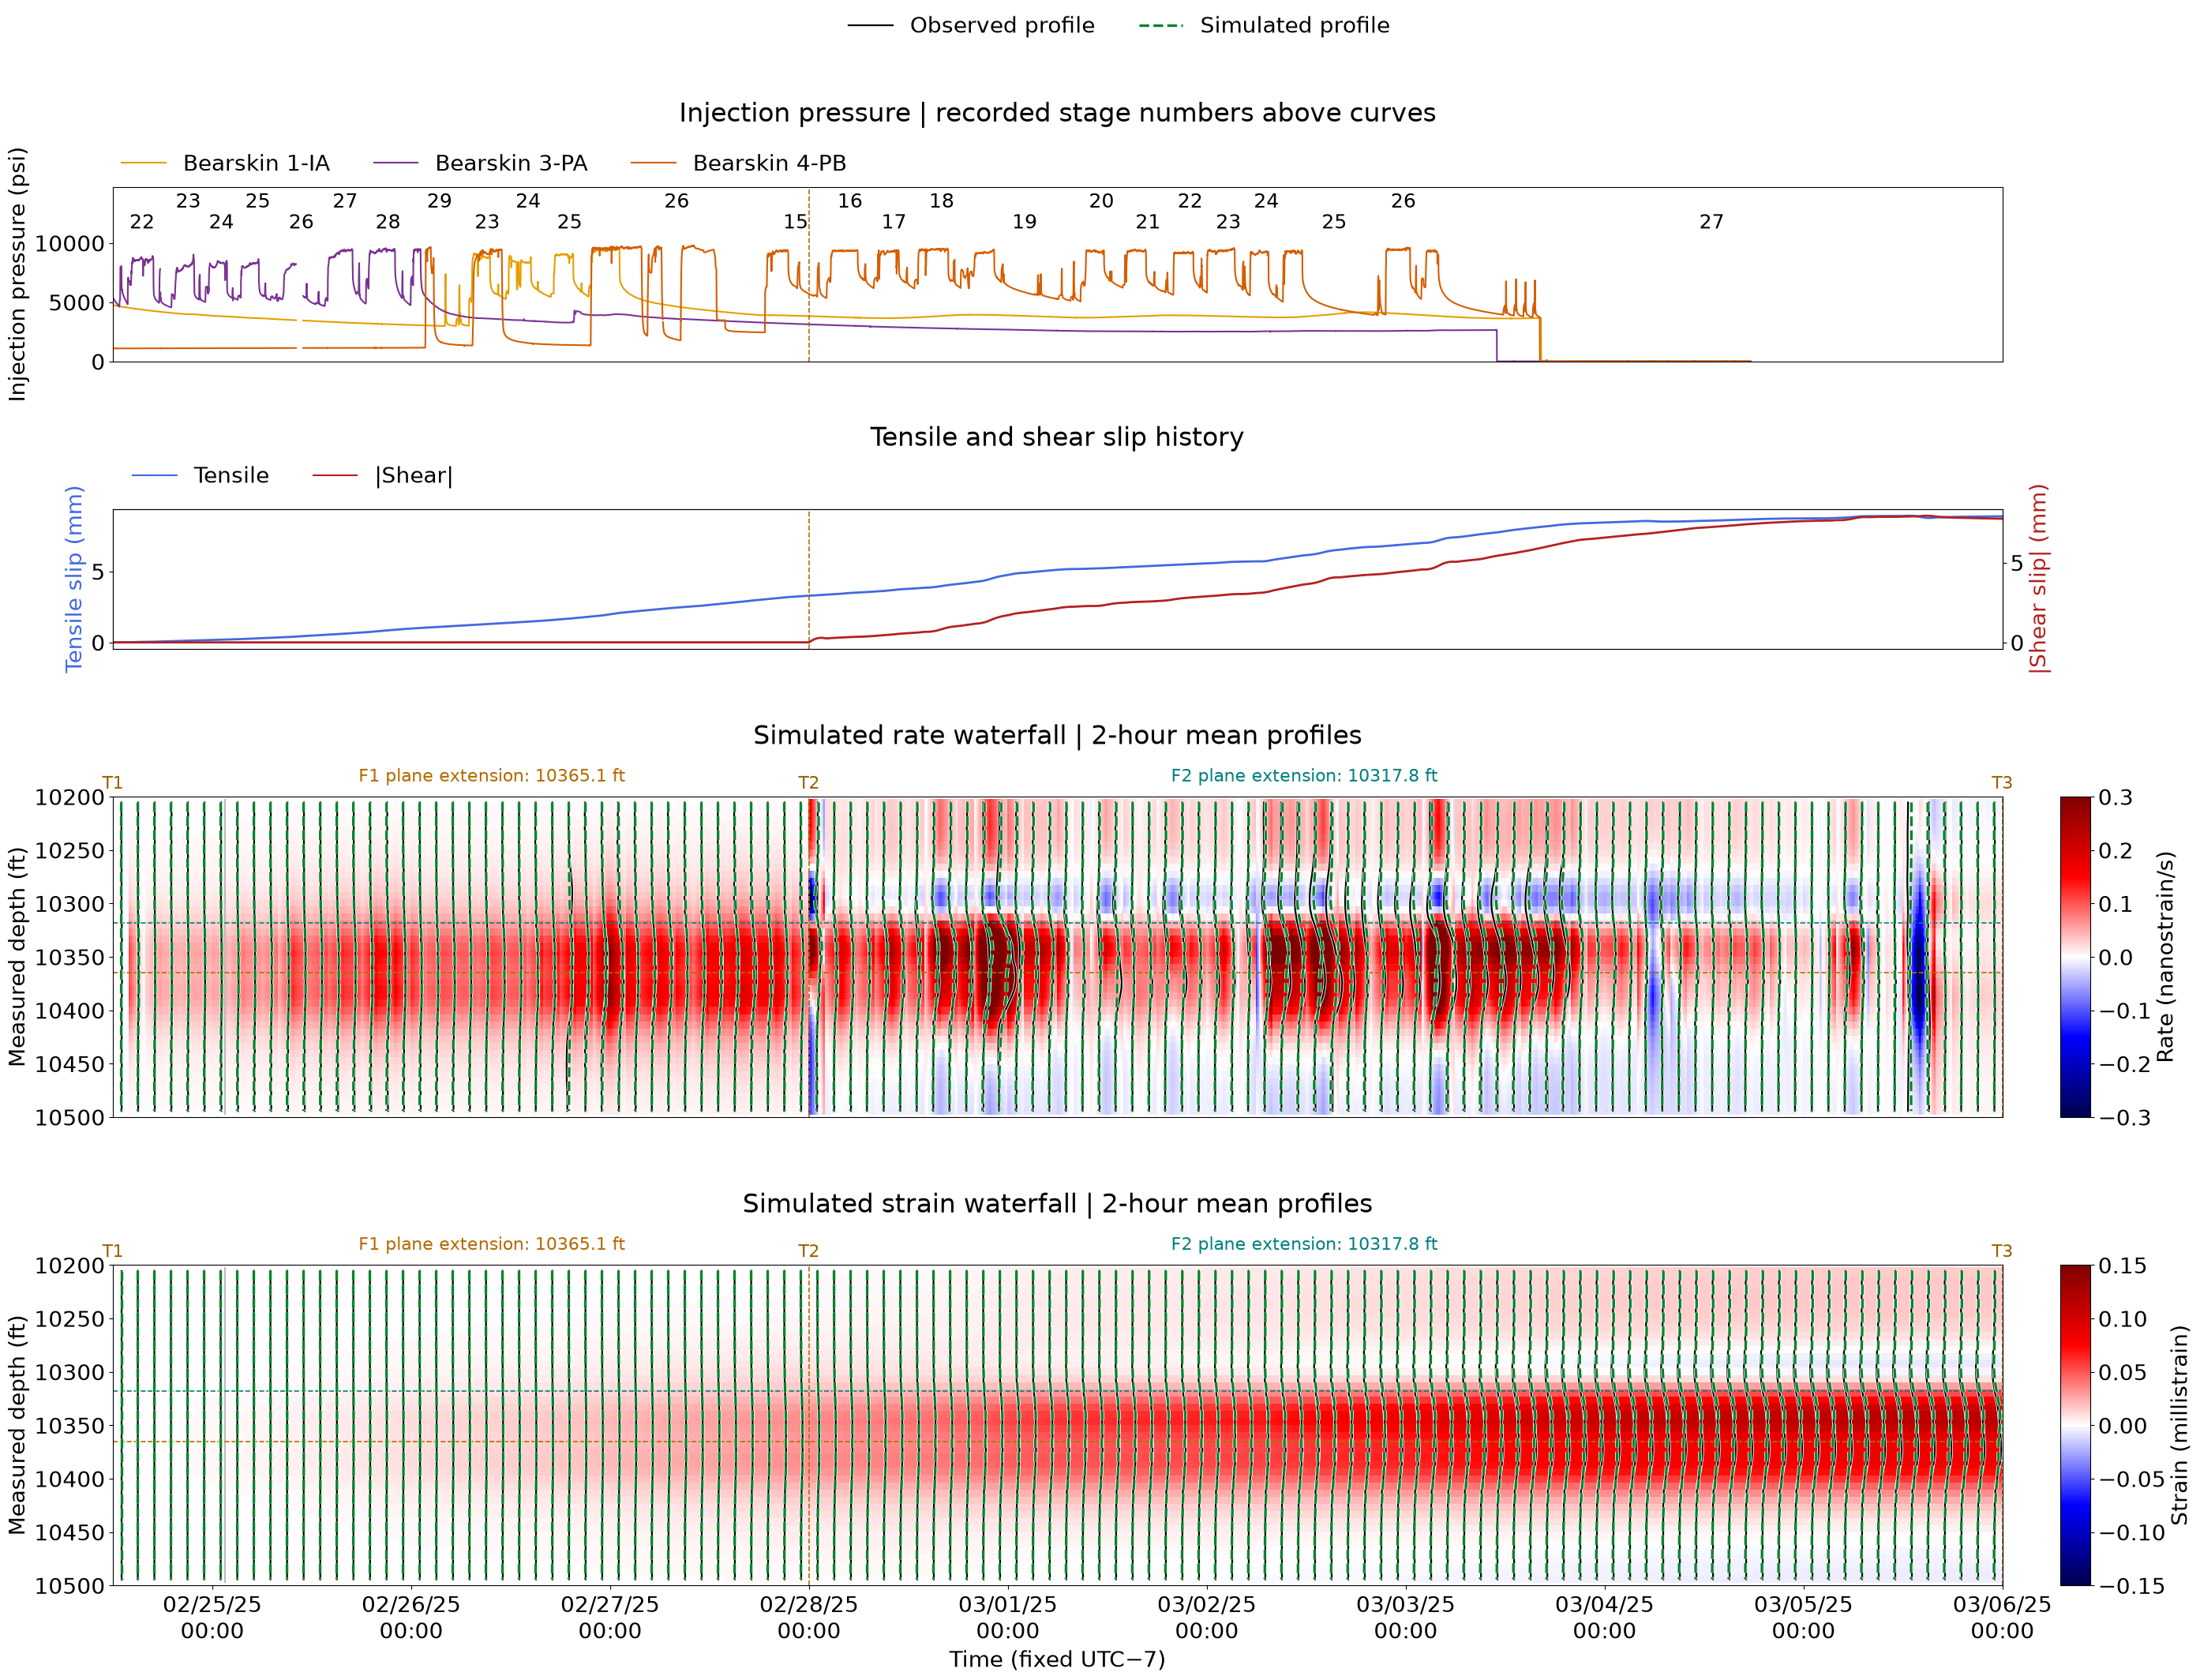

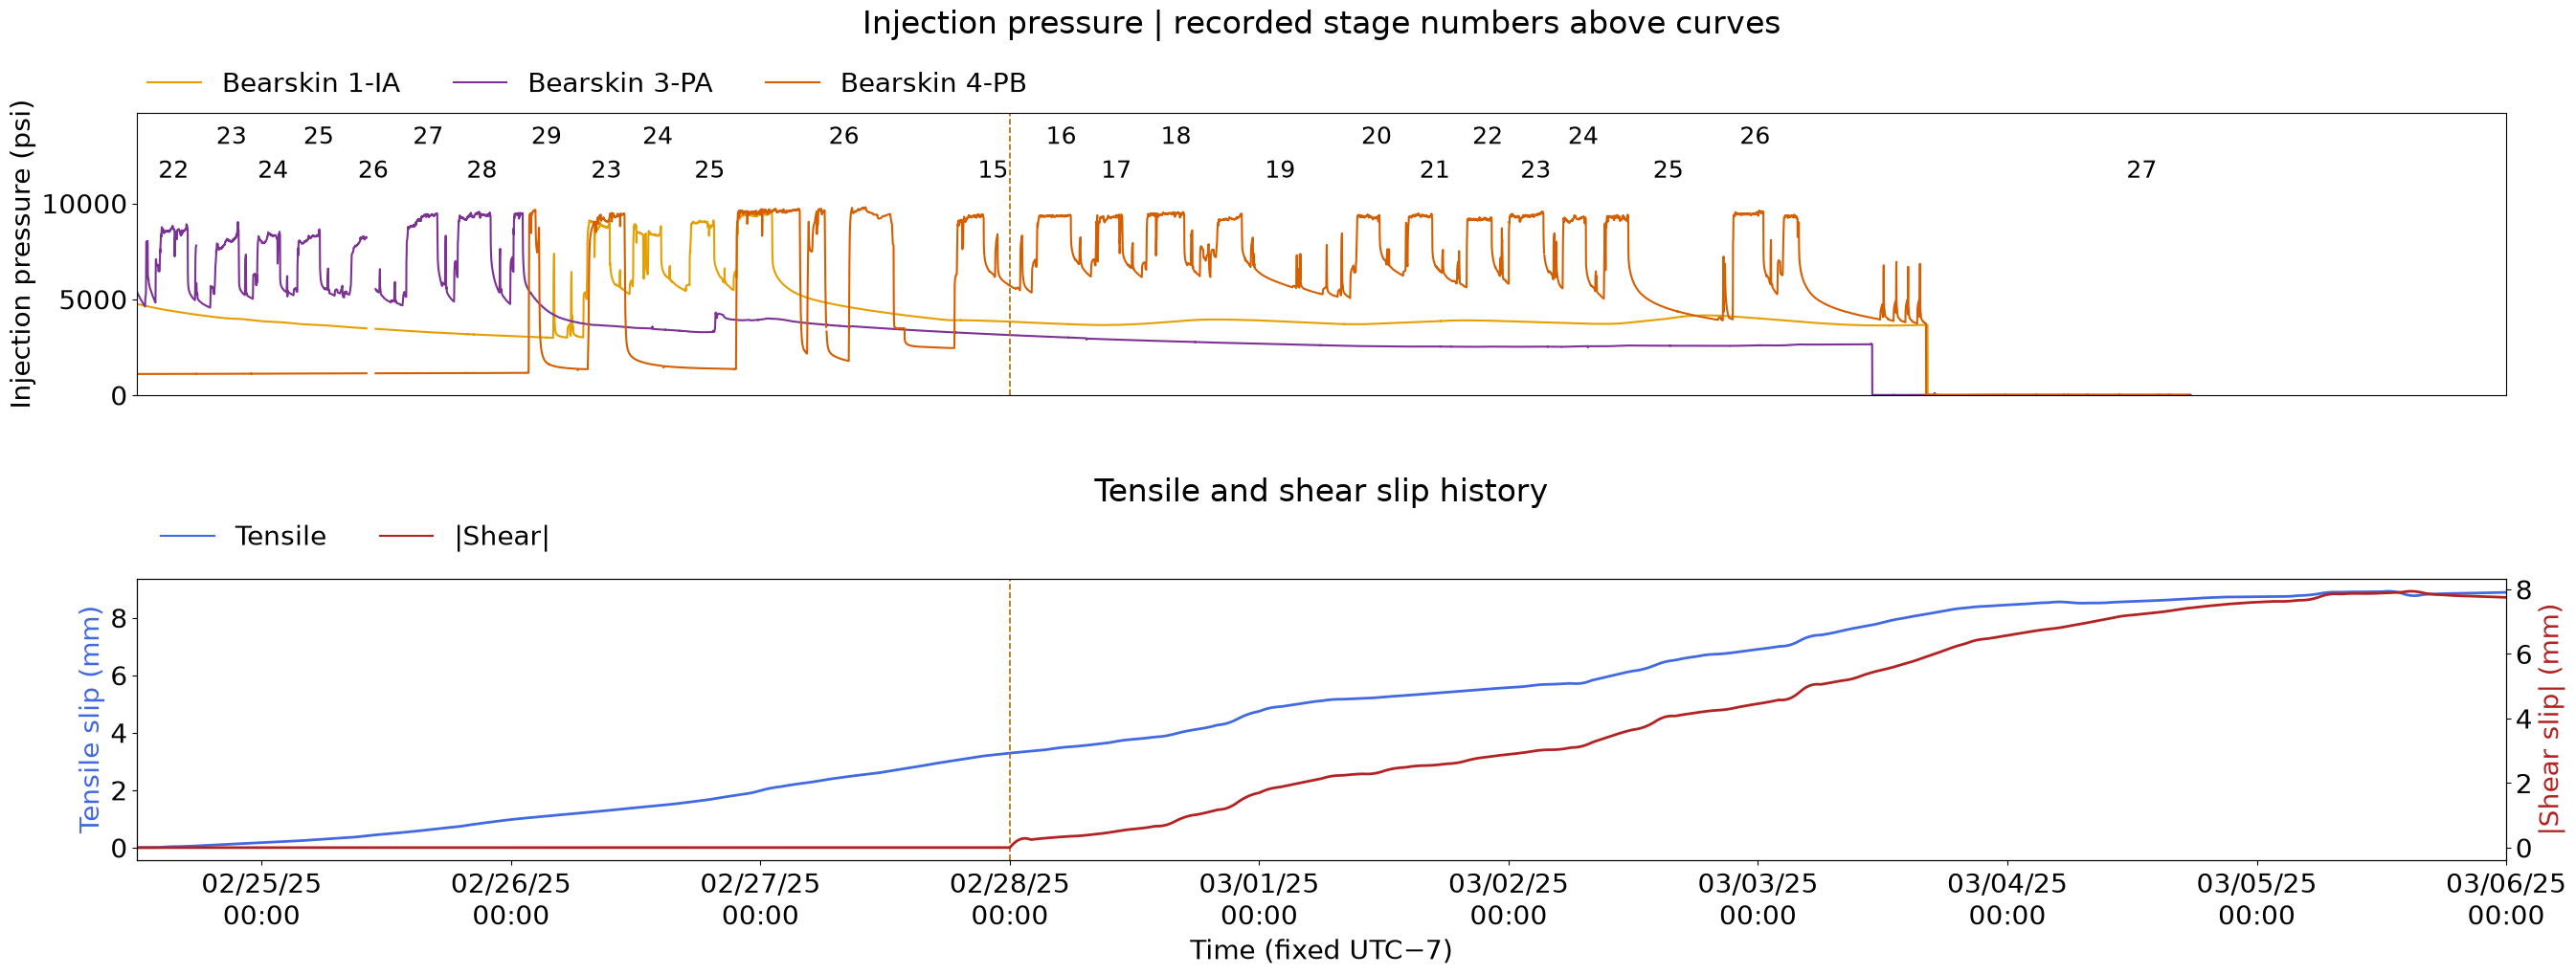

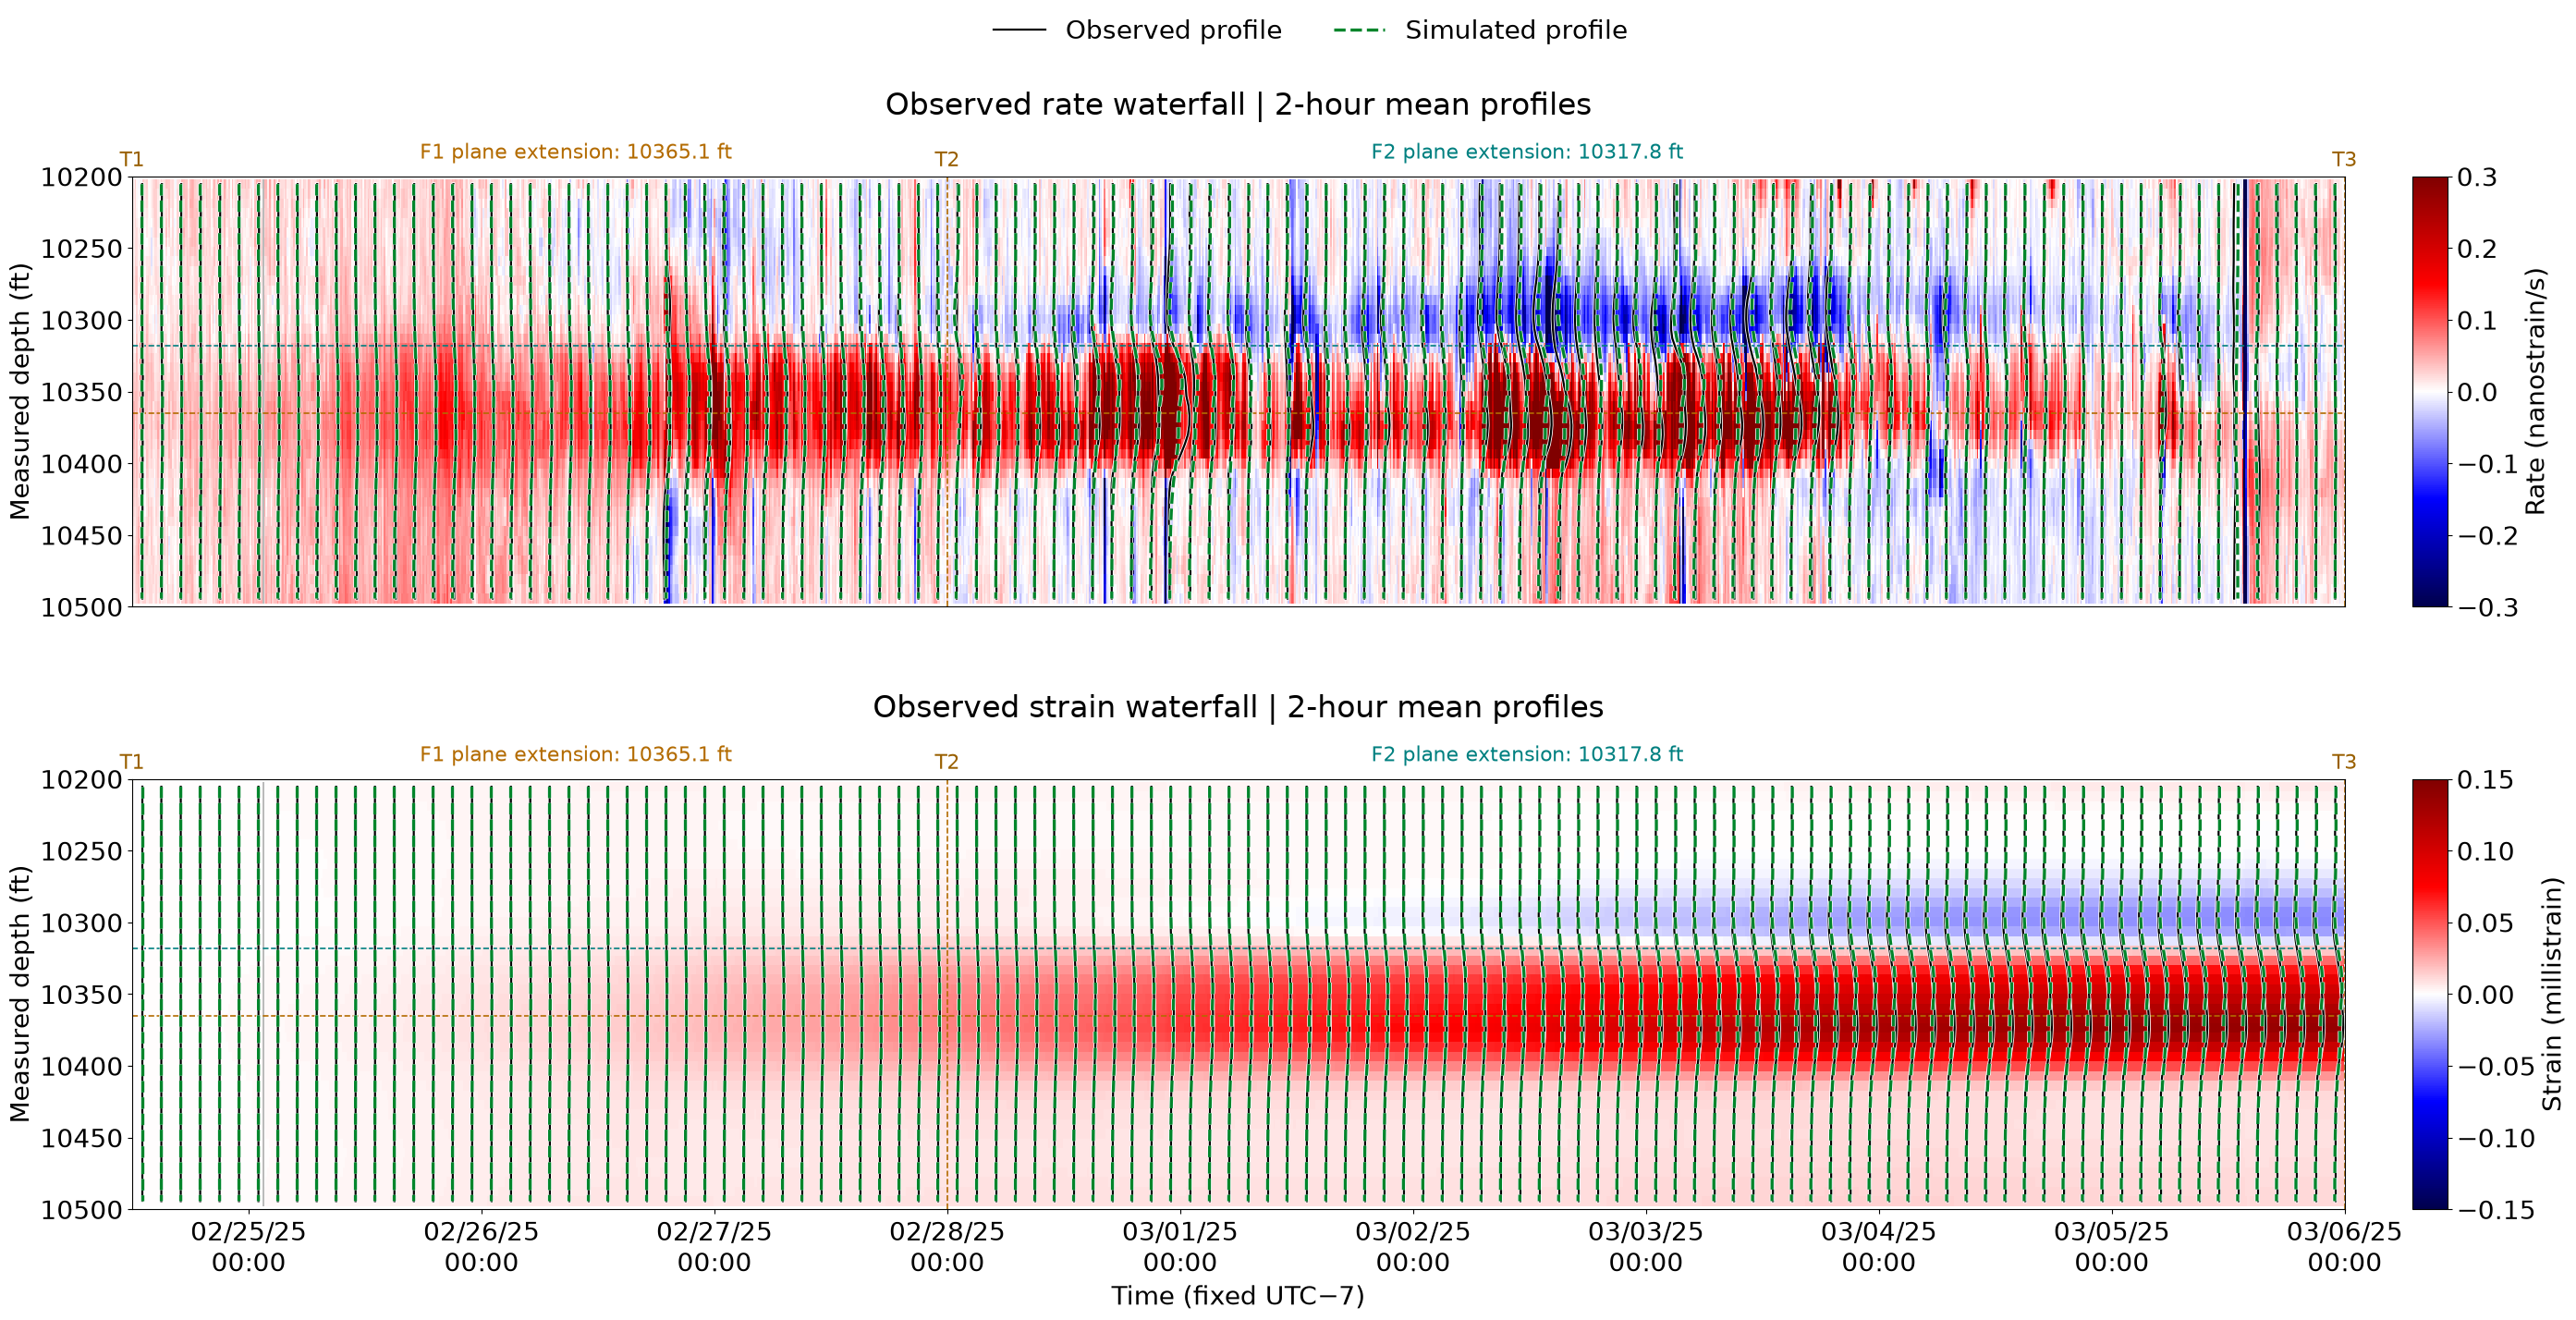

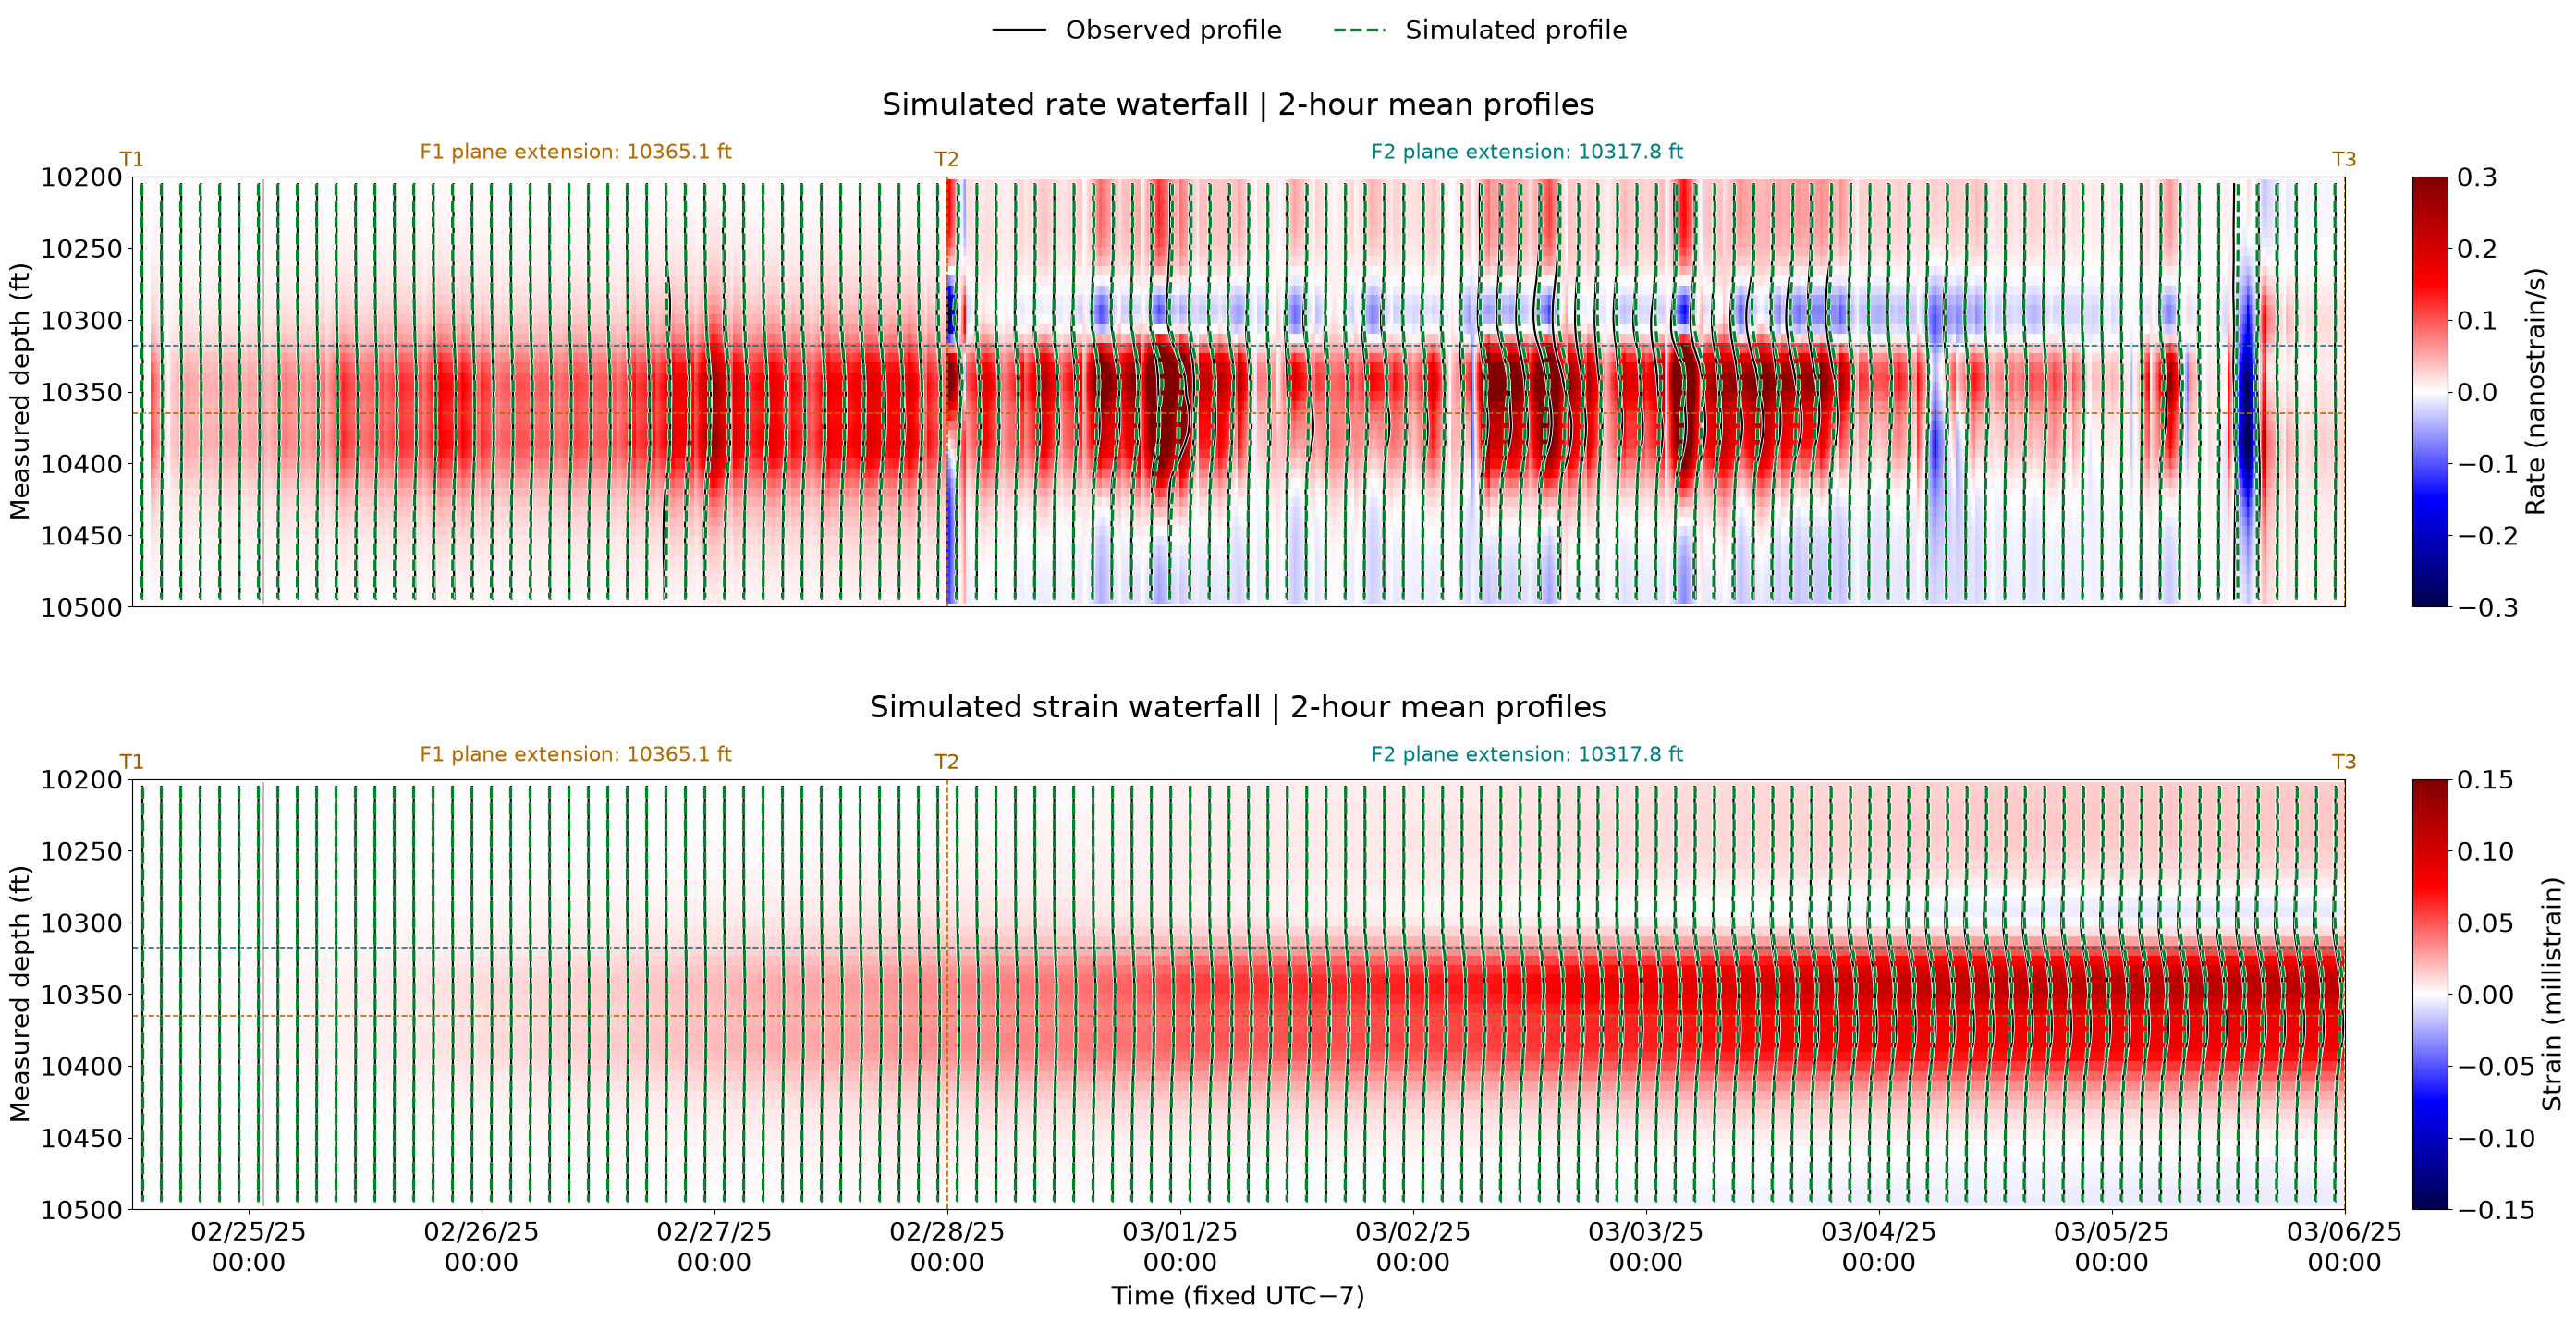

In [12]:
# Cell 14 | Modified 2026-09-22 22:49:18 MDT — Create the separate strain-targeted workflow with half-height F1.
# Cell 14 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 14 | Modified 2026-09-20 22:37:10 MDT — Shared-axis pressure, slip and waterfall diagnostics
# Purpose: Show recorded pressure stages and slip alongside observed and simulated strain-rate/strain waterfalls.
injection=pd.read_csv(OUT/'injection_pressure.csv',parse_dates=['time'])
plot_summary(obs,final,injection,'Inverted_strain_fit_two_hour_slip_history')
plot_summary(obs,final,injection,'Inverted_strain_fit_two_hour_slip_history',background='simulated')
plot_pressure_slip(obs,final,injection,'Inverted_strain_fit_two_hour_slip_history')
plot_comparison(obs,final,'inverted')